# Pre-processing Text
Let's now look at a more complete pre-processing of some text.

In [27]:
import nltk
import matplotlib.pyplot as plt

## Classification
For this example, we will presume we are pre-processing in order to prepare data for a text classification task.

We have a number of stories that are either about dancing or acting.  We want to use to use these stories to build a classification model so that we can classify other stories as about "dancing" or "acting".


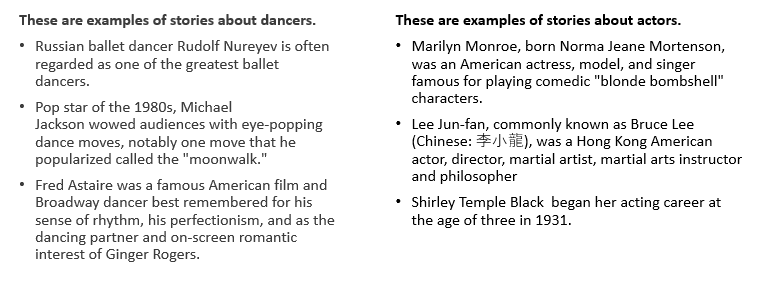



Can we use these examples to find what words indicate a story is about dancers or actors?
What if we had 10million stories and 1000 categories?  Could we devise a system to “learn” how to classify stories to those categories?


As a human, you would home in on certain words that are indicative of the story type:

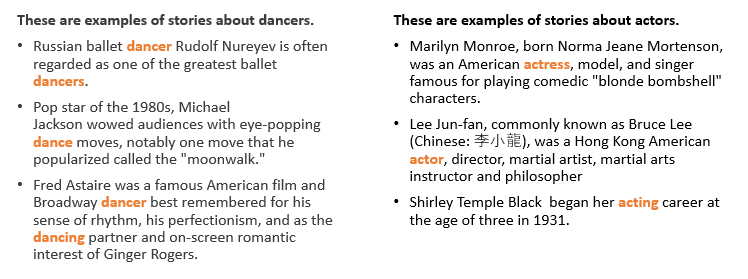

We won't actually build the classification model here, but we will explore how we can obtain some really useful features from these texts that could be used by a classification algorithm.

Let's first put our stories into a list:

In [28]:
stories = [""] * 6

# Three about dancing
stories[0] = "Russian ballet dancer Rudolf Nureyev is often regarded as one of the greatest ballet dancers."
stories[1] = "Pop star of the 1980s, Michael Jackson wowed audiences with eye-popping dance moves, notably one move that he popularized called the 'moonwalk.'"
stories[2] = "Fred Astaire was a famous American film and Broadway dancer best remembered for his sense of rhythm, his perfectionism, and as the dancing partner and on-screen romantic interest of Ginger Rogers."

# Three about acting
stories[3] = "Marilyn Monroe, born Norma Jeane Mortenson, was an American actress, model, and singer famous for playing comedic 'blonde bombshell' characters."
stories[4] = "Lee Jun-fan, commonly known as Bruce Lee (Chinese: 李小龍), was a Hong Kong American actor, director, martial artist, martial arts instructor and philosopher"
stories[5] = "Shirley Temple Black  began her acting career at the age of three in 1931."


In [29]:
# Define a helper function to plot freq dist of words in a list of lists
def plotfreq(x, title=""):
    # Flatten list of lists
    flat = []
    for i in x:
        flat += i
        
    # Get freq distribution of tokens
    f = nltk.FreqDist(flat)
    
    # Plot freq dist
    plt.figure(figsize=(12,3))
    
    plt.title(title)
    f.plot()

### Tokenise
Our first step is to tokenise the stories, splitting them up into words.

In [30]:
from nltk.tokenize import word_tokenize

tokens = []
for story in stories:
    words = word_tokenize(story)
    tokens.append(words)

In [31]:
tokens

[['Russian',
  'ballet',
  'dancer',
  'Rudolf',
  'Nureyev',
  'is',
  'often',
  'regarded',
  'as',
  'one',
  'of',
  'the',
  'greatest',
  'ballet',
  'dancers',
  '.'],
 ['Pop',
  'star',
  'of',
  'the',
  '1980s',
  ',',
  'Michael',
  'Jackson',
  'wowed',
  'audiences',
  'with',
  'eye-popping',
  'dance',
  'moves',
  ',',
  'notably',
  'one',
  'move',
  'that',
  'he',
  'popularized',
  'called',
  'the',
  "'moonwalk",
  '.',
  "'"],
 ['Fred',
  'Astaire',
  'was',
  'a',
  'famous',
  'American',
  'film',
  'and',
  'Broadway',
  'dancer',
  'best',
  'remembered',
  'for',
  'his',
  'sense',
  'of',
  'rhythm',
  ',',
  'his',
  'perfectionism',
  ',',
  'and',
  'as',
  'the',
  'dancing',
  'partner',
  'and',
  'on-screen',
  'romantic',
  'interest',
  'of',
  'Ginger',
  'Rogers',
  '.'],
 ['Marilyn',
  'Monroe',
  ',',
  'born',
  'Norma',
  'Jeane',
  'Mortenson',
  ',',
  'was',
  'an',
  'American',
  'actress',
  ',',
  'model',
  ',',
  'and',
  'singer

We can plot a word frequency distribution.  Notice that the most frequent words are "of" and "the" and even the punctuation ",".  These are not very useful words for distinguishing between stories about dancers and actors!

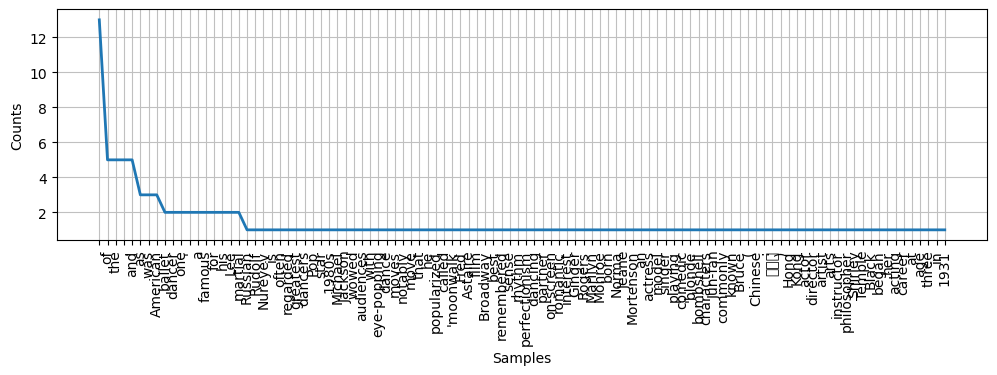

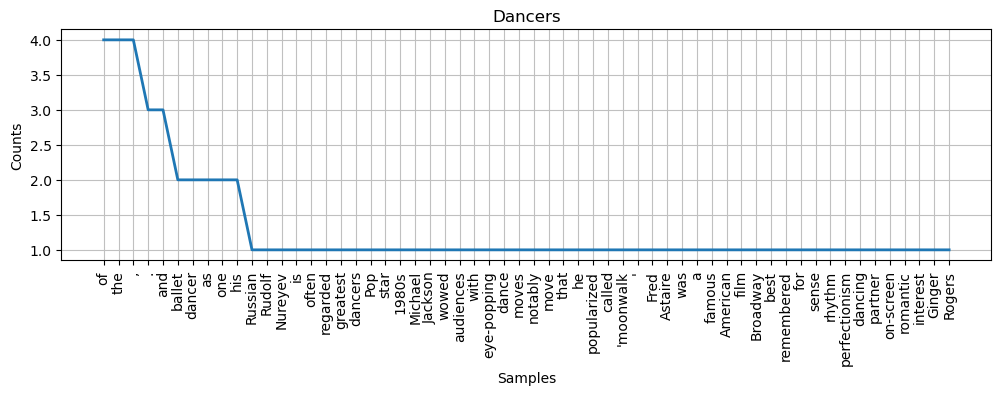

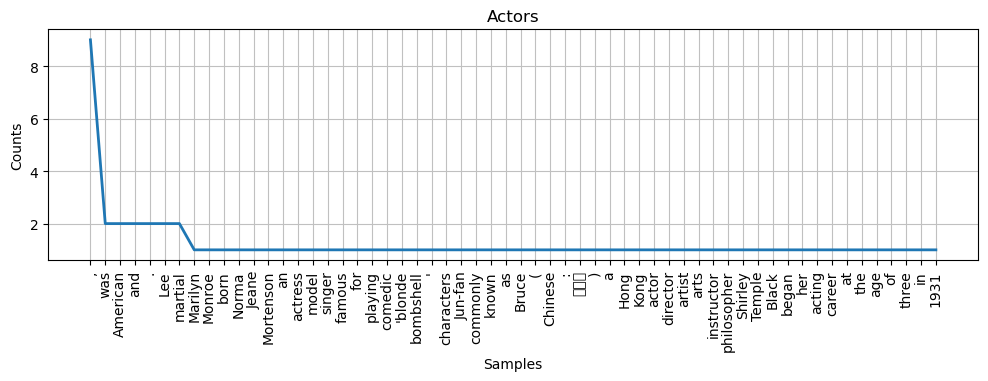

In [32]:
plotfreq(tokens)
plotfreq(tokens[0:3], "Dancers") # dancers
plotfreq(tokens[3:6], "Actors") # actors

### Remove punctuation
Let's first remove the punctuation.

In [33]:
tokens

[['Russian',
  'ballet',
  'dancer',
  'Rudolf',
  'Nureyev',
  'is',
  'often',
  'regarded',
  'as',
  'one',
  'of',
  'the',
  'greatest',
  'ballet',
  'dancers',
  '.'],
 ['Pop',
  'star',
  'of',
  'the',
  '1980s',
  ',',
  'Michael',
  'Jackson',
  'wowed',
  'audiences',
  'with',
  'eye-popping',
  'dance',
  'moves',
  ',',
  'notably',
  'one',
  'move',
  'that',
  'he',
  'popularized',
  'called',
  'the',
  "'moonwalk",
  '.',
  "'"],
 ['Fred',
  'Astaire',
  'was',
  'a',
  'famous',
  'American',
  'film',
  'and',
  'Broadway',
  'dancer',
  'best',
  'remembered',
  'for',
  'his',
  'sense',
  'of',
  'rhythm',
  ',',
  'his',
  'perfectionism',
  ',',
  'and',
  'as',
  'the',
  'dancing',
  'partner',
  'and',
  'on-screen',
  'romantic',
  'interest',
  'of',
  'Ginger',
  'Rogers',
  '.'],
 ['Marilyn',
  'Monroe',
  ',',
  'born',
  'Norma',
  'Jeane',
  'Mortenson',
  ',',
  'was',
  'an',
  'American',
  'actress',
  ',',
  'model',
  ',',
  'and',
  'singer

In [59]:
for word in tokens:
    print(word)

['Russian', 'ballet', 'dancer', 'Rudolf', 'Nureyev', 'is', 'often', 'regarded', 'as', 'one', 'of', 'the', 'greatest', 'ballet', 'dancers', '.']
['Pop', 'star', 'of', 'the', '1980s', ',', 'Michael', 'Jackson', 'wowed', 'audiences', 'with', 'eye-popping', 'dance', 'moves', ',', 'notably', 'one', 'move', 'that', 'he', 'popularized', 'called', 'the', "'moonwalk", '.', "'"]
['Fred', 'Astaire', 'was', 'a', 'famous', 'American', 'film', 'and', 'Broadway', 'dancer', 'best', 'remembered', 'for', 'his', 'sense', 'of', 'rhythm', ',', 'his', 'perfectionism', ',', 'and', 'as', 'the', 'dancing', 'partner', 'and', 'on-screen', 'romantic', 'interest', 'of', 'Ginger', 'Rogers', '.']
['Marilyn', 'Monroe', ',', 'born', 'Norma', 'Jeane', 'Mortenson', ',', 'was', 'an', 'American', 'actress', ',', 'model', ',', 'and', 'singer', 'famous', 'for', 'playing', 'comedic', "'blonde", 'bombshell', "'", 'characters', '.']
['Lee', 'Jun-fan', ',', 'commonly', 'known', 'as', 'Bruce', 'Lee', '(', 'Chinese', ':', '李小龍', 

In [35]:
cleaned_tokens = []
for t in tokens:
    cleaned = [word for word in t if word.isalpha()]
    cleaned_tokens.append(cleaned)

The word frequency plots are now cleaner:

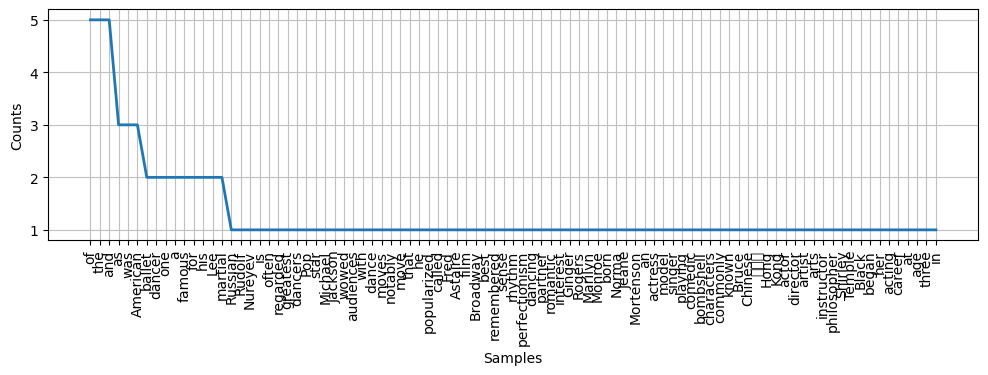

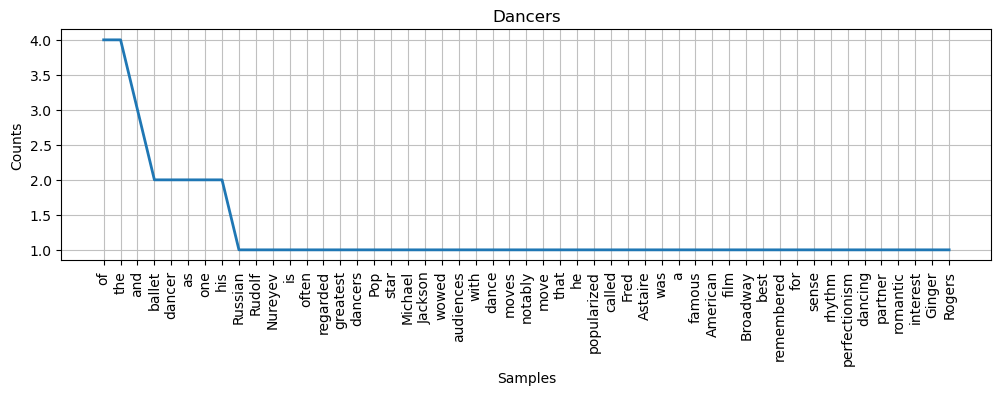

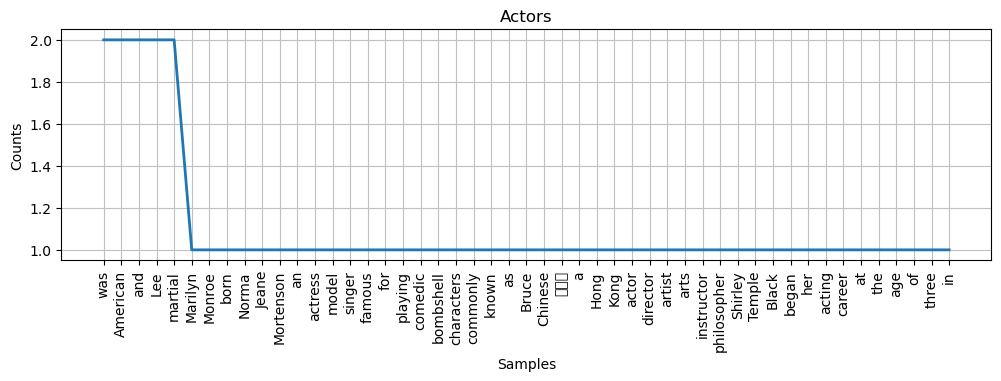

In [36]:
plotfreq(cleaned_tokens)
plotfreq(cleaned_tokens[0:3], "Dancers") # dancers
plotfreq(cleaned_tokens[3:6], "Actors") # actors

### Remove stopwords
Now let's remove the stopwords.  These are common English words that have little information value in natural language understanding.  Similar stop word lists exist in other languages (just substitute the language string).

In [37]:
from nltk.corpus import stopwords
stop_words = stopwords.words('english')
print(stop_words)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [38]:
stopwords_removed_tokens = []
for t in cleaned_tokens:
    cleaned = [word for word in t if not word in stop_words]
    stopwords_removed_tokens.append(cleaned)

Now looking at the word frequencies, we are starting to see more meaningful words appear at the top - e.g. ballet, dancer.  However, for the actor stories, the actor-related words (actress, actor, acting) are appearing with low frequencies so are not being considered as very meaningful.

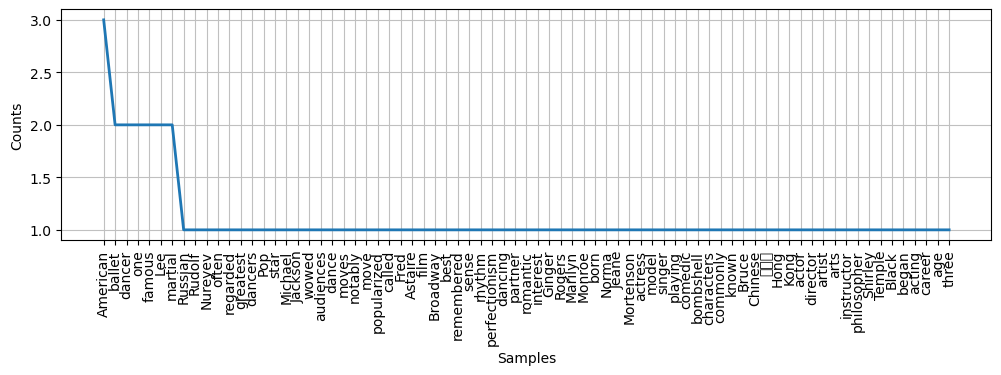

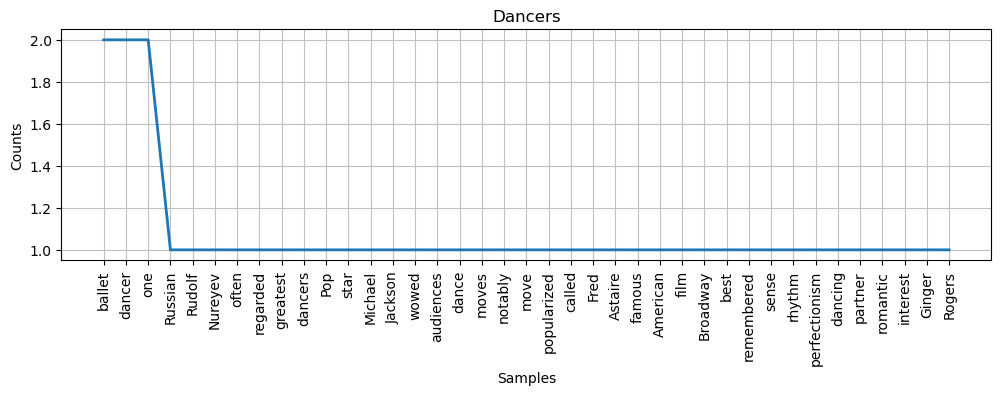

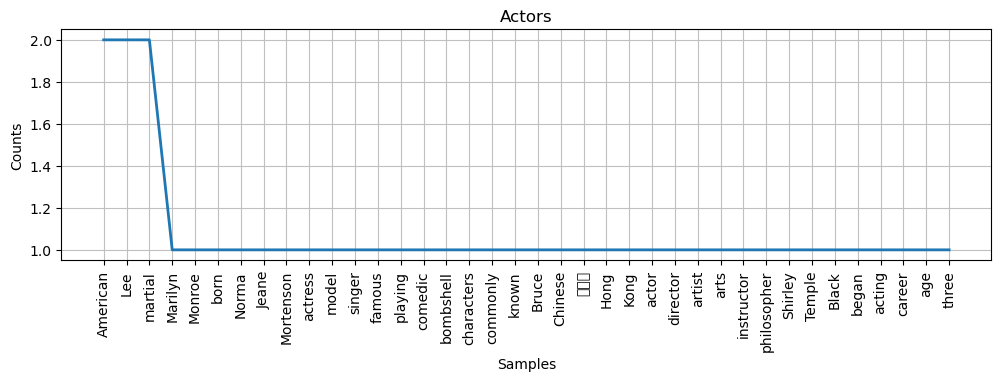

In [39]:
plotfreq(stopwords_removed_tokens)
plotfreq(stopwords_removed_tokens[0:3], "Dancers") # dancers
plotfreq(stopwords_removed_tokens[3:6], "Actors") # actors

### Stem
We can start to address the issue above where the actor-related words (actress, actor, acting) are not appearing at the top of the list, by using stemming.

Let's stem all words and then do the frequency count.

In [40]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
stemmed_tokens = []
for t in stopwords_removed_tokens:
    cleaned = [ps.stem(word) for word in t]
    stemmed_tokens.append(cleaned)

In [41]:
from nltk.stem import LancasterStemmer
ls = LancasterStemmer()
stemmed_tokens = []
for t in stopwords_removed_tokens:
    cleaned = [ls.stem(word) for word in t]
    stemmed_tokens.append(cleaned)

As you can see in the plot below, the stem "act" has bubbled up to near the top.  The stemming hasn't stemmed the word "actress" and perhaps in this case it would have helped.

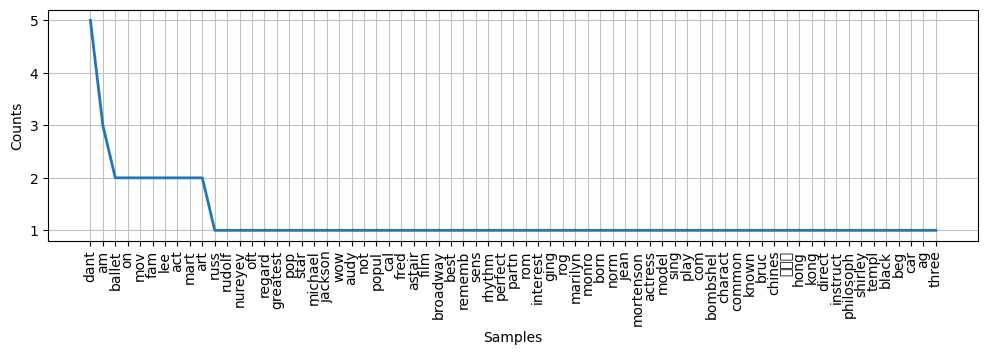

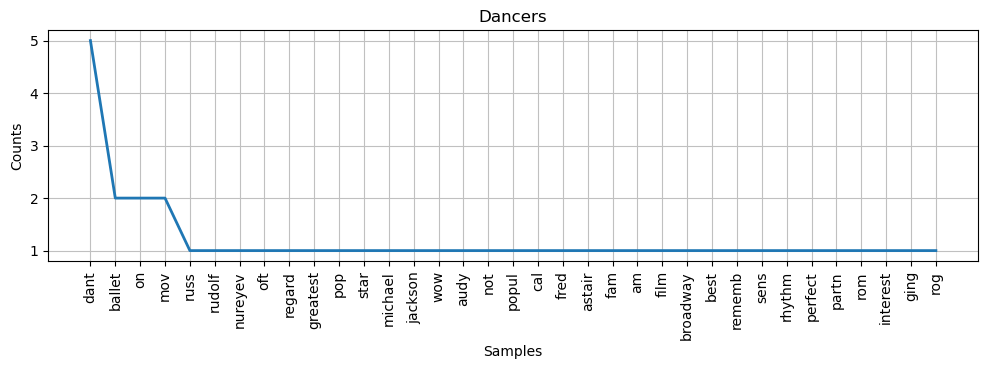

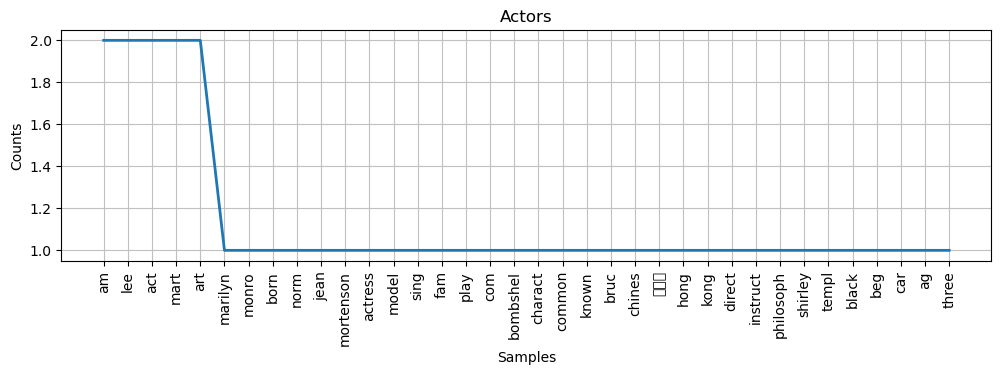

In [42]:
plotfreq(stemmed_tokens)
plotfreq(stemmed_tokens[0:3], "Dancers") # dancers
plotfreq(stemmed_tokens[3:6], "Actors") # actors

## Lemmatization
Does lemmatization give us better rules?  No, not for this classifcation task!  But maybe if I had more stories it would perform better.

In [43]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_tokens = []
for t in stopwords_removed_tokens:
    cleaned = [lemmatizer.lemmatize(word) for word in t]
    lemmatized_tokens.append(cleaned)
    

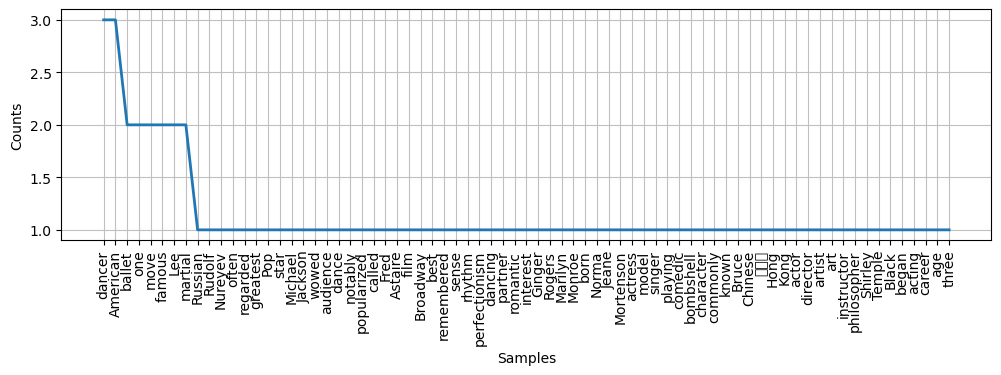

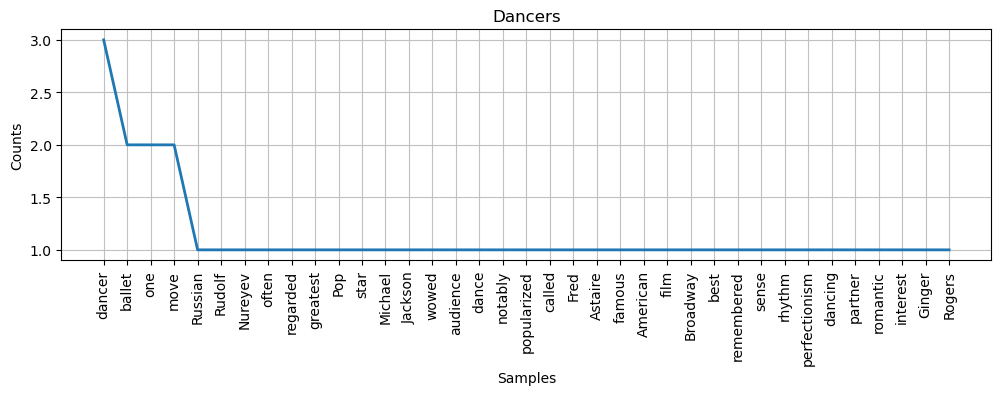

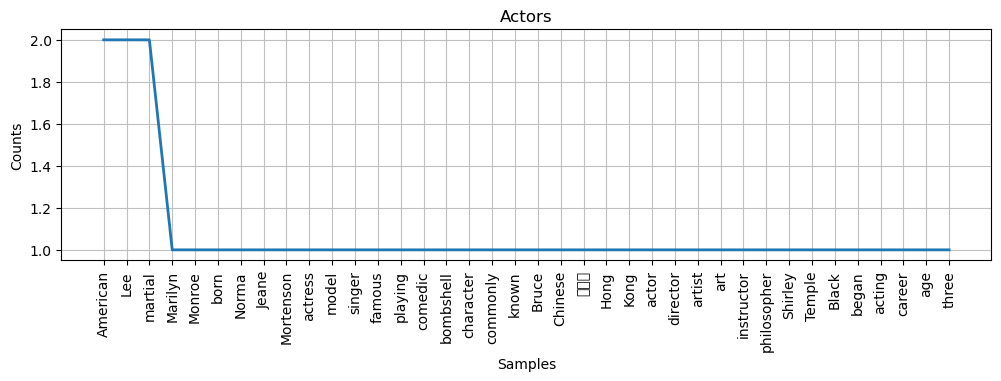

In [44]:
plotfreq(lemmatized_tokens)
plotfreq(lemmatized_tokens[0:3], "Dancers") # dancers
plotfreq(lemmatized_tokens[3:6], "Actors") # actors

## Summary

### Dancers

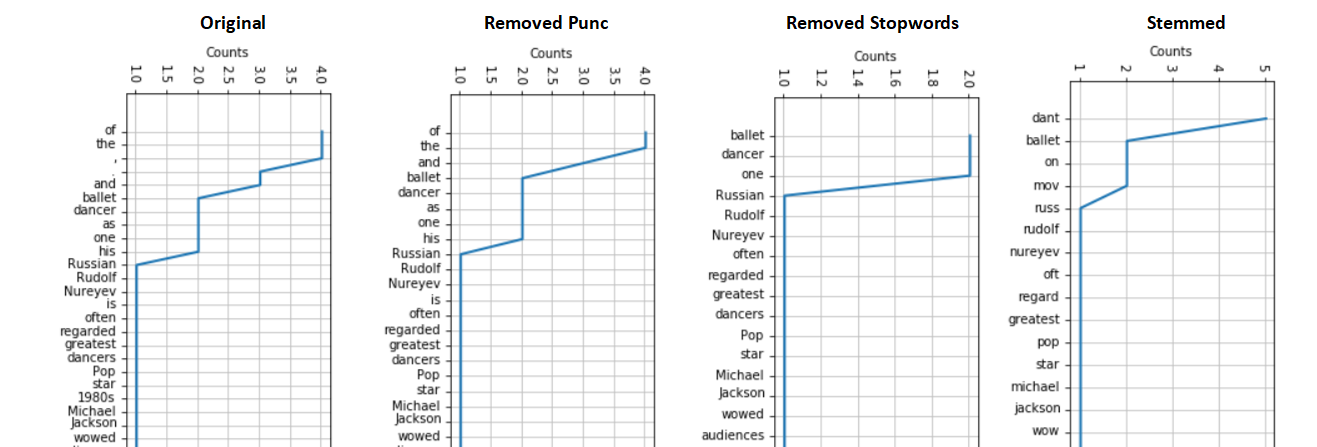

### Actors

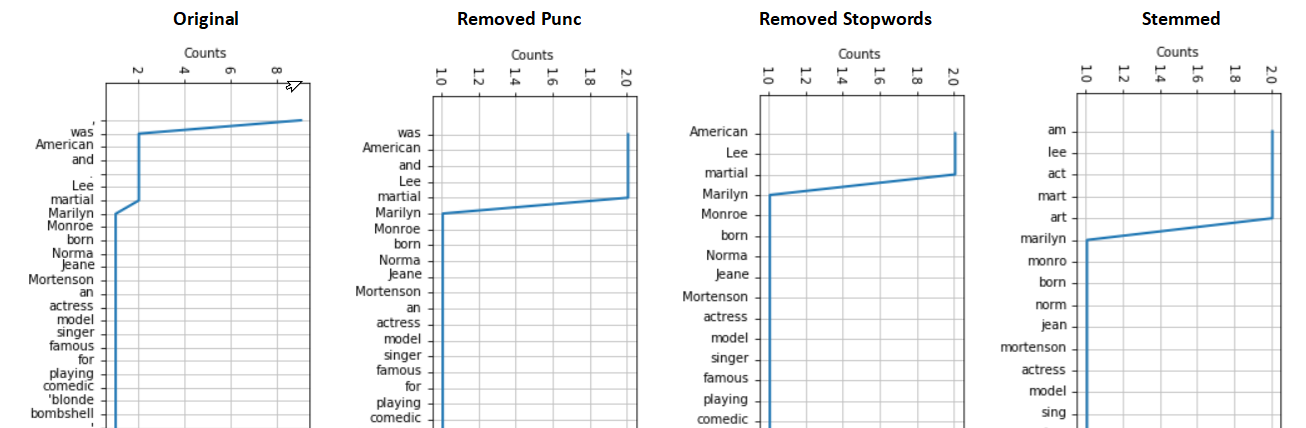

In [47]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import string
import re

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+', '', text)
    
    # Remove non-alphabetic characters
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Tokenize text
    words = text.split()
    
    # Remove stop words and short words, lemmatize
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    
    # Join words back into a single string
    return ' '.join(words)

In [52]:
stories_dancer_clean = [preprocess_text(story) for story in stories[0:3]]


In [53]:
stories_actor_clean = [preprocess_text(story) for story in stories[3:6]]

In [55]:
stories_dancer_clean

['russian ballet dancer rudolf nureyev often regarded one greatest ballet dancer',
 'pop star michael jackson wowed audience eyepopping dance move notably one move popularized called moonwalk',
 'fred astaire famous american film broadway dancer best remembered sense rhythm perfectionism dancing partner onscreen romantic interest ginger rogers']

In [66]:
stories_actor_clean

['marilyn monroe born norma jeane mortenson american actress model singer famous playing comedic blonde bombshell character',
 'lee junfan commonly known bruce lee chinese hong kong american actor director martial artist martial art instructor philosopher',
 'shirley temple black began acting career age three']

In [71]:
split_dancer_stories = [story.split() for story in stories_dancer_clean]

In [72]:
split_actor_stories = [story.split() for story in stories_actor_clean]

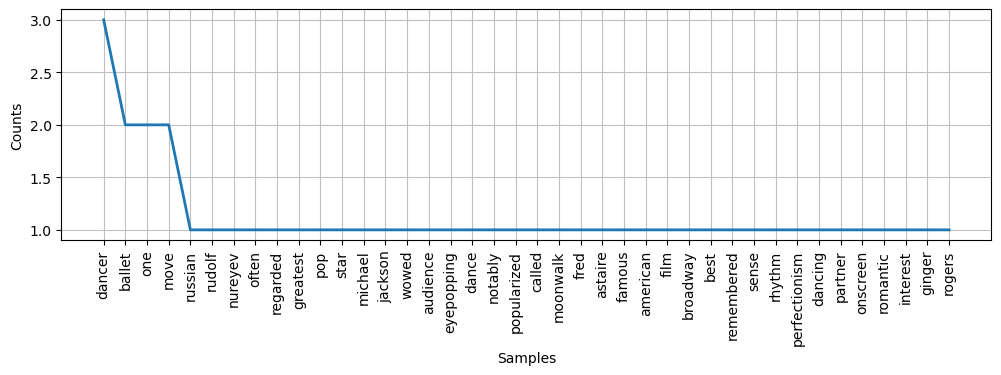

In [73]:
plotfreq(split_dancer_stories)

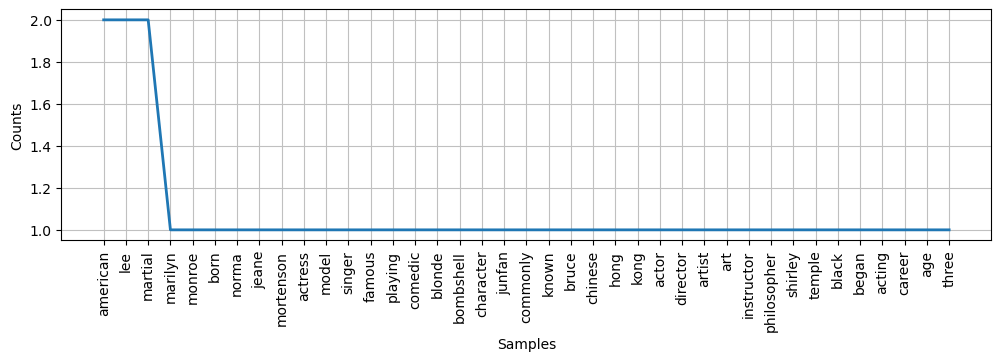

In [74]:
plotfreq(split_actor_stories)

In [105]:
import nltk
from nltk.corpus import subjectivity #The subjectivity corpus in NLTK contains subjective and objective sentences. 


from nltk.sentiment import SentimentAnalyzer # The SentimentAnalyzer class in NLTK is a tool for 
# analyzing the sentiment of text.

from nltk.sentiment.util import mark_negation # The mark_negation function is used to handle negations in text. It modifies the text 
#by appending a _NEG suffix to words that appear in a negated context. 

from nltk.corpus import subjectivity
from nltk.classify import NaiveBayesClassifier
# Sample text data
text = "What is a millionaire's outfit of the day like? For property agent Kevin Lim, it seems like branded labels from head to toe, and paired with a $40,000 watch. This was revealed by ERA Singapore on Monday (Oct 23) which has raised plenty of eyebrows online. In a TikTok video titled 'asking millionaires how much is their outfit,' Lim said that his Celine sweater is 'probably' around $1,500. Lim, who is ERA Singapore's chief agency officer, added that his jeans and shoes from the same French luxury clothing brand cost around $2,000 and $1,200 respectively. When it came to the accessories, the 43-year-old said that his chain from Japanese jewelry maker Goro Takahashi is an eye-popping $10,000. The Audemars Piguet timepiece on his wrist? A cool $40,000, Lim said, while flashing his pearly whites for the camera. In the video, ERA Singapore said that his 'outfit price' is a whopping $54,700. In the next segment of the 44-second video, Lim was asked if he has any tips 'to be a millionaire' like himself. Letting out a laugh, he said: 'Don't buy stupid stuff like that. Use the gains from investments. You know, other people's money. And then you can start buying stupid things.' The video, which has garnered over 100,000 views, has sparked much discussion on social media. Many netizens criticized ERA Singapore's decision to post it. One wrote that it was 'humble bragging at its finest,' and a second said that it was 'tasteless.' 'Show off here for what?' a netizen added. An AsiaOne reader, who declined to be named, labeled the video as distasteful. She added that it was shared at a time when 'cost of living has risen significantly in Singapore.' 'Those who have benefited from earning well such as property agents should just quietly enjoy their money and not flaunt it so distastefully like this.' 'Very humble and sporting' However, others were less critical, saying that the critics are 'jealous' and 'sour grapes.' 'He puts a lot of effort and spends his money on things he enjoys,' a netizen added. When one netizen said Lim was 'flexing hard,' ERA Singapore said that he is 'actually very humble and sporting.' ERA Singapore said on their website that Lim 'embodies success.' 'At age 27, he enjoyed financial independence by making his first million dollars. He started along the track of success at just 22, using his sales acumen and an understanding of market trends to catapult him in the re"

# Tokenize the text
tokens = nltk.word_tokenize(text)


In [106]:
n_instances

100

In [102]:
# Load the subjectivity dataset
n_instances = 100
subj_docs = [(sent, 'subj') for sent in subjectivity.sents(categories='subj')[:n_instances]]
obj_docs = [(sent, 'obj') for sent in subjectivity.sents(categories='obj')[:n_instances]]

In [103]:
len(subj_docs), len(obj_docs)

(100, 100)

In [107]:
# Create a training and test set for subjective docs.  80% go in training, save 20% for testing
train_subj_docs = subj_docs[:80]
test_subj_docs = subj_docs[80:100]

# Create a training and test set for objective docs.  80% go in training, save 20% for testing
train_obj_docs = obj_docs[:80]
test_obj_docs = obj_docs[80:100]

# Merge the training sets and the test sets
training_docs = train_subj_docs+train_obj_docs
testing_docs = test_subj_docs+test_obj_docs


In [108]:
len(training_docs),len(testing_docs)

(160, 40)

In [109]:

def extract_unigram_feats(document, unigrams, handle_negation=False):
    """
    Populate a dictionary of unigram features, reflecting the presence/absence in the document
    of each of the tokens in `unigrams`.

    :param document: a list of words/tokens.
    :param unigrams: a list of words/tokens whose presence/absence has to be checked in `document`.
    :param handle_negation: if `handle_negation == True` apply `mark_negation` method to `document`
                            before checking for unigram presence/absence.
    :return: a dictionary of unigram features {unigram : boolean}.
    """
    features = {}
    if handle_negation:
        document = mark_negation(document)
    for word in unigrams:
        features[f"contains({word})"] = word in set(document)
    return features

In [110]:
# Initialize a SentimentAnalyzer
sentim_analyzer = SentimentAnalyzer()

# Extract features for classification
all_words = list(sentim_analyzer.all_words([mark_negation(doc) for doc in training_docs]))

# Create a feature set using unigrams
unigram_feats = sentim_analyzer.unigram_word_feats(all_words, min_freq=4)
sentim_analyzer.add_feat_extractor(extract_unigram_feats, unigrams=unigram_feats)

In [111]:
# Initialize a SentimentAnalyzer
trainer_naive_bayes = NaiveBayesClassifier.train

# Create feature sets for classification
features = []

for (words, sentiment) in train_subj_docs + train_obj_docs:
    words = mark_negation(words)
    features.extend([({word: True for word in words}, sentiment)])

# Train a NaiveBayesClassifier
classifier = trainer_naive_bayes(features)

# Classify the input text
text_features = mark_negation(tokens)
text_features = {word: True for word in text_features}
classification = classifier.classify(text_features)

# Print the classification
print(f"The text is classified as: {classification}")






The text is classified as: subj


In [114]:

from nltk.classify import NaiveBayesClassifier
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import mark_negation, extract_unigram_feats

# Initialize the SentimentAnalyzer
sentim_analyzer = SentimentAnalyzer()

# Add feature extractors
all_words_neg = sentim_analyzer.all_words([mark_negation(doc) for doc in train_obj_docs + train_subj_docs])
unigram_feats = sentim_analyzer.unigram_word_feats(all_words_neg, min_freq=4)
sentim_analyzer.add_feat_extractor(extract_unigram_feats, unigrams=unigram_feats)

# Apply features to obtain a feature-value representation of our datasets
training_docs = train_obj_docs + train_subj_docs
training_set = sentim_analyzer.apply_features(training_docs)

# Train the NaiveBayesClassifier
trainer = NaiveBayesClassifier.train
classifier = sentim_analyzer.train(trainer, training_set)

# Classify the input text
text_features = sentim_analyzer.apply_features([mark_negation(text.split())])
classification = classifier.classify(text_features[0][0])

# Print the classification
print(f"The text is classified as: {classification}")


Training classifier
The text is classified as: obj
